# pyTDI Sagnac Kappa Example

This notebook tests whether pyTDI Sagnac variables can be used as the data vector for the coronagraphic kappa construction.

What it does:

1. Loads an existing simulated source with pyTDI-compatible HDF5 products.
2. Computes pyTDI `ALPHA/BETA/GAMMA` Sagnac variables.
3. Converts those Sagnac variables to frequency domain.
4. Applies the existing static coronagraphic projection `kappa = A(f, sky) . (alpha,beta,gamma)`.
5. Compares against the current static-link Sagnac implementation on the same chunk.

Important: this is a convention test. The current kappa projection is still the static first-generation response model, so a pyTDI Sagnac output is not assumed to be a drop-in replacement until the conventions agree.

In [1]:
from pathlib import Path
import os
import json
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "scripts").exists() and (PROJECT_ROOT.parent / "scripts").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)

CONFIG = PROJECT_ROOT / "test-run" / "config.yaml"
CATALOG = PROJECT_ROOT / "test-run" / "catalog.csv"
RUNS_ROOT = PROJECT_ROOT / "test-run" / "simulations"
SOURCE_ID = "smbhb_m1e6"
OUT_DIR = PROJECT_ROOT / "test-run" / "pytdi_sagnac_kappa_example"

print(PROJECT_ROOT)
print(OUT_DIR)

/Users/shubhanshutiwari/IdeaProjects/LISA-TF
/Users/shubhanshutiwari/IdeaProjects/LISA-TF/test-run/pytdi_sagnac_kappa_example


## Run pyTDI Sagnac Kappa

The default uses `ALPHA1/BETA1/GAMMA1`, because the existing kappa projection is a static first-generation Sagnac construction.

`--max-samples 65536` keeps the CSV and plots compact. Use `--max-samples 0` to process the full science segment.

In [2]:
!conda run -n lisa-tf python scripts/pytdi_sagnac_kappa_example.py \
  --config {CONFIG} \
  --catalog {CATALOG} \
  --runs-root {RUNS_ROOT} \
  --source-id {SOURCE_ID} \
  --source noisy \
  --generation 1 \
  --max-samples 65536 \
  --output-dir {OUT_DIR}

{
  "config": {
    "dt": 0.1,
    "science_duration": 150000.0,
    "burn_in_seconds": 600.0,
    "center_waveform_peak": true,
    "ra": 0.7,
    "dec": -0.55,
    "central_freq_hz": 281600000000000.0,
    "orbit_name": "esa-trailing",
    "orbit_dt": 600.0,
    "orbit_duration_factor": 5.0,
    "orbit_start_offset_seconds": null,
    "orbit_dataset": "tps/ppr",
    "gw_dataset": "tps",
    "seed": 24680,
    "frequency_low_hz": 1e-05,
    "frequency_high_hz": 0.1,
    "tdi_generation": 2,
    "interpolation_order": 31,
    "tdi_unit": "frequency",
    "extra_skipped": 0,
    "edge_crop": 0,
    "instrument_kwargs": {}
  },
  "source_id": "smbhb_m1e6",
  "source": "noisy",
  "pytdi_sagnac_generation": 1,
  "pytdi_eta_combinations": false,
  "sky_ra": 0.7,
  "sky_dec": -0.55,
  "n_samples": 65536,
  "dt_s": 0.10000000000582077,
  "kappa_time_csv": "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/test-run/pytdi_sagnac_kappa_example/pytdi_sagnac_kappa_timeseries.csv",
  "plots": [
    "/Us

## Inspect Summary

The key diagnostic is `pytdi_static_real_correlation`. If the pyTDI Sagnac variables and the static-link Sagnac variables have matching conventions, this should become large in magnitude after accounting for scaling/sign. A value near zero means the observable conventions or delay model are not aligned.

In [3]:
summary = json.loads((OUT_DIR / "summary.json").read_text())
print(json.dumps({
    "source_id": summary["source_id"],
    "source": summary["source"],
    "pytdi_sagnac_generation": summary["pytdi_sagnac_generation"],
    "pytdi_eta_combinations": summary["pytdi_eta_combinations"],
    "n_samples": summary["n_samples"],
    "pytdi_static_real_correlation": summary["pytdi_static_real_correlation"],
    "pytdi_rms": summary["pytdi_rms"],
    "static_rms": summary["static_rms"],
}, indent=2))

{
  "source_id": "smbhb_m1e6",
  "source": "noisy",
  "pytdi_sagnac_generation": 1,
  "pytdi_eta_combinations": false,
  "n_samples": 65536,
  "pytdi_static_real_correlation": 0.005762102088564595,
  "pytdi_rms": 0.00019786448561711026,
  "static_rms": 136.8697420991426
}


## Plot Outputs

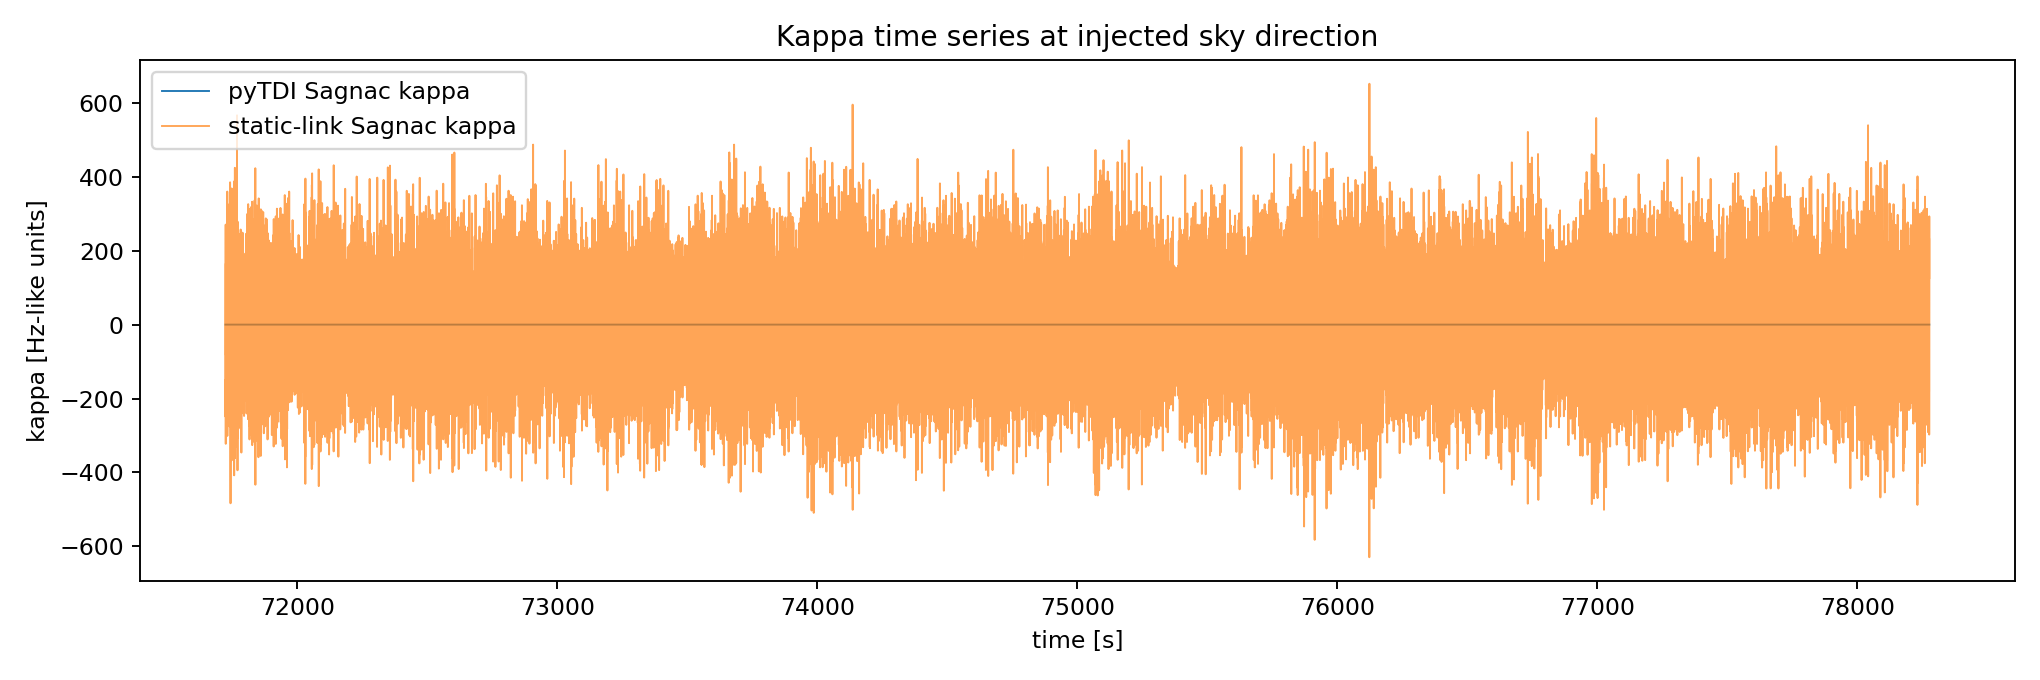

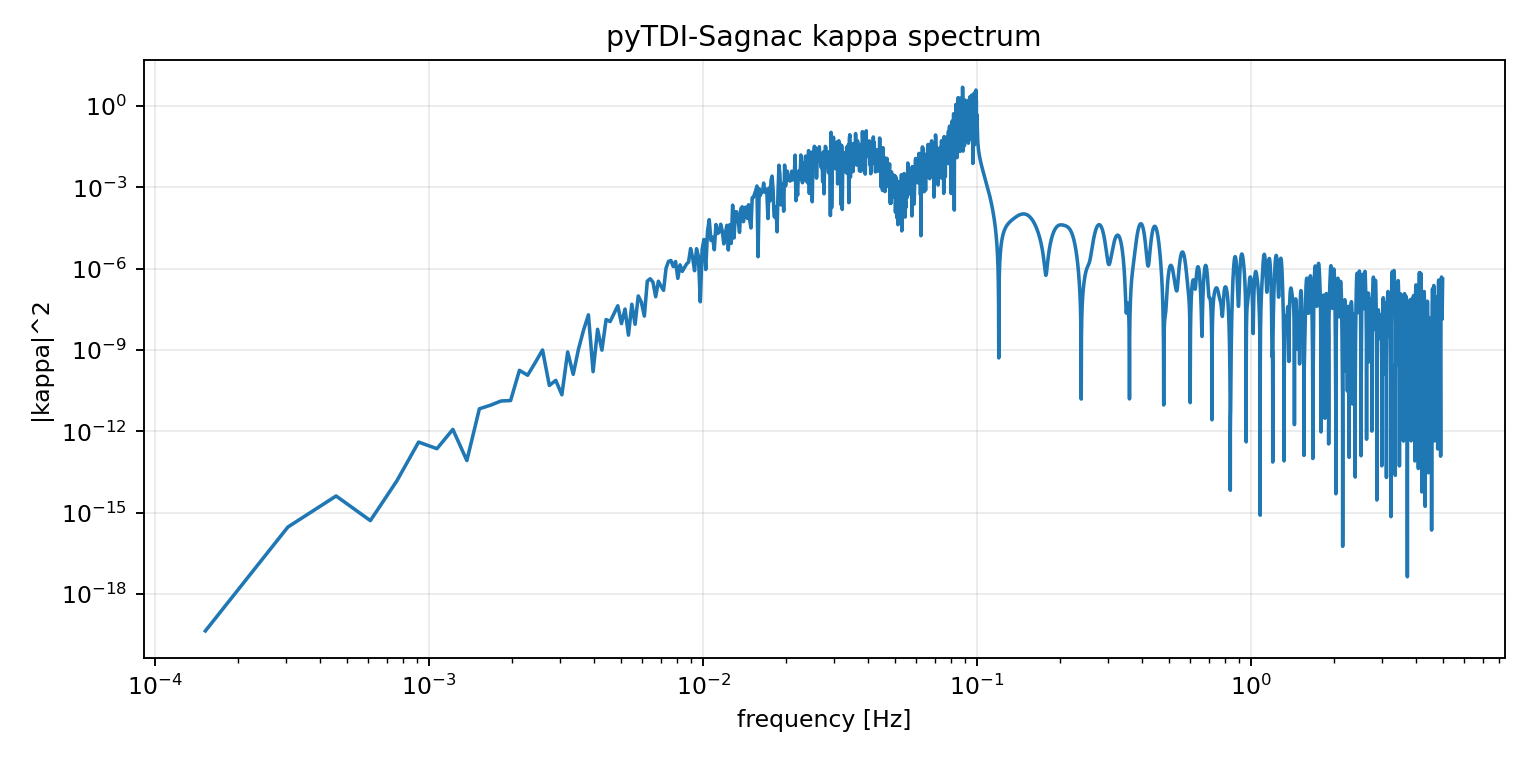

In [4]:
for name in [
    "plots/pytdi_vs_static_kappa_time.png",
    "plots/pytdi_kappa_spectrum.png",
]:
    path = OUT_DIR / name
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print(f"Missing {path}")

## Optional: Try pyTDI ETA Sagnac Variables

pyTDI also exposes `ALPHA1_ETA/BETA1_ETA/GAMMA1_ETA`. Run this if the standard Sagnac convention does not match the static-link implementation.

In [5]:
ETA_OUT_DIR = PROJECT_ROOT / "test-run" / "pytdi_sagnac_kappa_example_eta"

!conda run -n lisa-tf python scripts/pytdi_sagnac_kappa_example.py \
  --config {CONFIG} \
  --catalog {CATALOG} \
  --runs-root {RUNS_ROOT} \
  --source-id {SOURCE_ID} \
  --source noisy \
  --generation 1 \
  --eta-combinations \
  --max-samples 65536 \
  --output-dir {ETA_OUT_DIR}

You are using a measurement file in a version that might not be fully supported (got '2.1.0', official support up to '2.0')
Traceback (most recent call last):
  File "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/scripts/pytdi_sagnac_kappa_example.py", line 347, in <module>
    main()
  File "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/scripts/pytdi_sagnac_kappa_example.py", line 272, in main
    t, freqs, alpha_f, beta_f, gamma_f = evaluate_pytdi_sagnac(
                                         ^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/shubhanshutiwari/IdeaProjects/LISA-TF/scripts/pytdi_sagnac_kappa_example.py", line 131, in evaluate_pytdi_sagnac
    raise KeyError(
KeyError: "pyTDI *_ETA Sagnac combinations require eta_ij measurements, but these are missing: ['eta_12', 'eta_13', 'eta_21', 'eta_23', 'eta_31', 'eta_32']. Available measurements: ref_12, ref_13, ref_21, ref_23, ref_31, ref_32, ref_sb_12, ref_sb_13, ref_sb_21, ref_sb_23, ref_sb_31, ref_sb_32, sci_12, sci_13, sci_21, sci_23, s

In [6]:
if (ETA_OUT_DIR / "summary.json").exists():
    eta_summary = json.loads((ETA_OUT_DIR / "summary.json").read_text())
    print(json.dumps({
        "pytdi_eta_combinations": eta_summary["pytdi_eta_combinations"],
        "pytdi_static_real_correlation": eta_summary["pytdi_static_real_correlation"],
        "pytdi_rms": eta_summary["pytdi_rms"],
        "static_rms": eta_summary["static_rms"],
    }, indent=2))

## Interpretation

If this example shows poor agreement, do not replace the current kappa Sagnac generator yet. The next checks are:

- Confirm whether kappa should use pyTDI `ALPHA*` or `ALPHA*_ETA` variables.
- Match Fourier transform sign and delay conventions.
- Decide whether the kappa response vector `A(f, sky)` must be rebuilt for pyTDI's exact Sagnac generation and time-dependent delays.
- Compare on `gw_only` as well as `noisy`, since noise can hide convention errors.